# Entrega 03 · Evaluación final: ¿aporta algo leer el texto?

Compara, **una sola vez** y sobre el conjunto reservado etiquetado a mano, cuatro sistemas definidos de antemano
en `docs/protocolo_evaluacion.md`:

| Sistema | Regla |
|---|---|
| **B1** | Alerta si estrellas ≤ 2 |
| **B2** | Alerta si estrellas ≤ 3 |
| **M** | Alerta si el modelo preentrenado (lee el **texto**) da P(≤3★) ≥ 0,5 |
| **C** | Alerta si B2 **o** M alertan |

**Reglas del experimento:** los umbrales no se ajustan con las etiquetas del conjunto reservado, y la evaluación
final (sección 3) se ejecuta una sola vez. Este notebook **no imprime texto de reseñas**: los casos a leer se
guardan en un fichero privado.

## 0. Preparación

In [11]:
import os, glob, math, sqlite3
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.figsize": (7, 3.2), "axes.spines.top": False, "axes.spines.right": False})

# ---- Parámetros FIJADOS en docs/protocolo_evaluacion.md (no se tocan) ----
PRE_MODEL = "nlptown/bert-base-multilingual-uncased-sentiment"
MODEL_MAX_STARS = 3        # el modelo puntúa P(<= 3 estrellas)
MODEL_THRESHOLD = 0.5      # umbral por defecto, NO ajustado

In [12]:
%pip install -q transformers torch

In [13]:
def find(pattern, dirs=("data", "../data", ".")):
    for d in dirs:
        hits = sorted(glob.glob(os.path.join(d, pattern)))
        if hits: return hits[0]
    return None

DB_PATH, LABELS_PATH = find("reviews*.db"), find("holdout_labels*.csv")
if DB_PATH is None or LABELS_PATH is None:        # en Colab: sube reviews.db y holdout_labels.csv
    from google.colab import files
    files.upload()
    DB_PATH, LABELS_PATH = find("reviews*.db"), find("holdout_labels*.csv")
print("BD:", DB_PATH, "| etiquetas:", LABELS_PATH)

con = sqlite3.connect(DB_PATH)
gold = pd.read_sql("select * from gold_reviews where has_text = 1", con)
hold_ids = pd.read_sql("select review_id from holdout_reviews", con)
labels = pd.read_csv(LABELS_PATH)

gold["es_holdout"] = gold.review_id.isin(hold_ids.review_id)
dev = gold[~gold.es_holdout].reset_index(drop=True)
hold = gold[gold.es_holdout].merge(labels, on="review_id", how="left").reset_index(drop=True)
assert hold.etiqueta.notna().all(), "Faltan etiquetas del conjunto reservado"
print(f"Desarrollo: {len(dev)} reseñas con texto | Reservado: {len(hold)}")
print("Etiquetas del reservado:", hold.etiqueta.value_counts().to_dict())

BD: ./reviews.db | etiquetas: ./holdout_labels.csv
Desarrollo: 329 reseñas con texto | Reservado: 109
Etiquetas del reservado: {'NO': 96, 'SI': 11, 'EXCLUIDA': 2}


## 1. Puntuar el texto con el modelo (sin entrenar nada)

In [14]:
from transformers import pipeline as hf_pipeline
clf = hf_pipeline("text-classification", model=PRE_MODEL, top_k=None, truncation=True, max_length=256)

def score_texts(texts):
    out = clf(list(texts), batch_size=16)
    # etiquetas '1 star' ... '5 stars' -> probabilidad de <= MODEL_MAX_STARS estrellas
    return np.array([sum(o["score"] for o in r if int(o["label"][0]) <= MODEL_MAX_STARS) for r in out])

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

In [15]:
dev["score_M"] = score_texts(dev.text)
hold["score_M"] = score_texts(hold.text)
print("Reseñas puntuadas:", len(dev) + len(hold))

Reseñas puntuadas: 438


## 2. Comprobación en desarrollo (solo para ver que el modelo se comporta)
Aquí el "correcto" son las estrellas (etiqueta débil). **No se ajusta nada con este resultado.**

In [16]:
y_dev = (dev.rating <= 3).astype(int); p_dev = (dev.score_M >= MODEL_THRESHOLD).astype(int)
tp = int(((p_dev == 1) & (y_dev == 1)).sum()); fp = int(((p_dev == 1) & (y_dev == 0)).sum()); fn = int(((p_dev == 0) & (y_dev == 1)).sum())
print(f"Desarrollo ({len(dev)} reseñas): el modelo marca {int(p_dev.sum())} | acierta {tp} de {tp+fn} reseñas de <=3★ | {fp} marcadas con >=4★")

Desarrollo (329 reseñas): el modelo marca 39 | acierta 30 de 37 reseñas de <=3★ | 9 marcadas con >=4★


## 3. Evaluación final en el conjunto reservado (EJECUTAR UNA SOLA VEZ)
Etiqueta humana: **SI** = requiere atención, **NO** = basta una plantilla. Las reseñas `EXCLUIDA` quedan fuera de las
métricas principales y se tratan en la sensibilidad (sección 5).

In [17]:
def wilson(k, n, z=1.96):
    if n == 0: return (np.nan, np.nan)
    p = k / n; den = 1 + z**2 / n
    centro = (p + z**2 / (2 * n)) / den
    mitad = z * math.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / den
    return (centro - mitad, centro + mitad)

def sistemas(d):
    b2 = d.rating <= 3; m = d.score_M >= MODEL_THRESHOLD
    return {"B1 · estrellas ≤2": (d.rating <= 2).astype(int), "B2 · estrellas ≤3": b2.astype(int),
            "M · modelo (texto)": m.astype(int), "C · B2 o M": (b2 | m).astype(int)}

def metricas(pred, y):
    tp = int(((pred == 1) & (y == 1)).sum()); fp = int(((pred == 1) & (y == 0)).sum())
    fn = int(((pred == 0) & (y == 1)).sum()); tn = int(((pred == 0) & (y == 0)).sum())
    p = tp / (tp + fp) if tp + fp else np.nan; r = tp / (tp + fn) if tp + fn else np.nan
    (pl, ph), (rl, rh) = wilson(tp, tp + fp), wilson(tp, tp + fn)
    return {"aciertos (TP)": tp, "falsas alarmas (FP)": fp, "no detectadas (FN)": fn, "TN": tn,
            "precisión": p, "IC95 prec.": f"{pl:.2f}-{ph:.2f}", "recall": r, "IC95 recall": f"{rl:.2f}-{rh:.2f}"}

ev = hold[hold.etiqueta.isin(["SI", "NO"])].reset_index(drop=True)
y = (ev.etiqueta == "SI").astype(int).values
tabla = pd.DataFrame({k: metricas(v.values, y) for k, v in sistemas(ev).items()}).T
print(f"Reseñas evaluables: {len(ev)} | críticas (SI): {int(y.sum())}")
display(tabla.style.format({"precisión": "{:.2f}", "recall": "{:.2f}"}))

Reseñas evaluables: 107 | críticas (SI): 11


,aciertos (TP),falsas alarmas (FP),no detectadas (FN),TN,precisión,IC95 prec.,recall,IC95 recall
B1 · estrellas ≤2,8,0,3,96,1.00,0.68-1.00,0.73,0.43-0.90
B2 · estrellas ≤3,9,1,2,95,0.90,0.60-0.98,0.82,0.52-0.95
M · modelo (texto),8,4,3,92,0.67,0.39-0.86,0.73,0.43-0.90
C · B2 o M,10,5,1,91,0.67,0.42-0.85,0.91,0.62-0.98


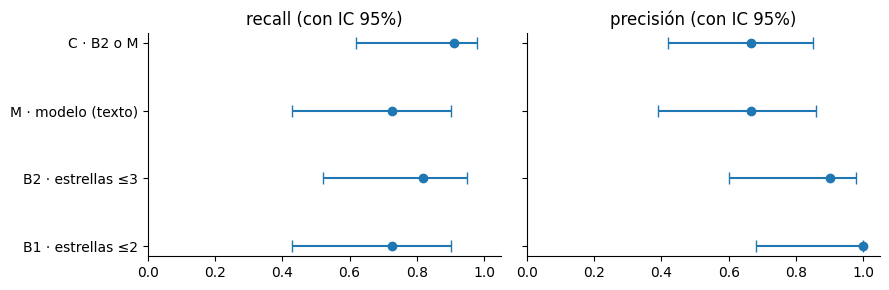

Con tan pocas críticas los intervalos son anchos: las diferencias pequeñas no son concluyentes.


In [18]:
fig, ax = plt.subplots(1, 2, figsize=(9, 3), sharey=True)
for a, (col, ic) in zip(ax, [("recall", "IC95 recall"), ("precisión", "IC95 prec.")]):
    v = tabla[col].astype(float).values
    lo = np.array([float(s.split("-")[0]) for s in tabla[ic]]); hi = np.array([float(s.split("-")[1]) for s in tabla[ic]])
    a.errorbar(v, range(len(v)), xerr=[v - lo, hi - v], fmt="o", capsize=4)
    a.set_yticks(range(len(v))); a.set_yticklabels(tabla.index); a.invert_yaxis()
    a.set_xlim(0, 1.05); a.set_title(col + " (con IC 95%)")
plt.tight_layout(); plt.show()
print("Con tan pocas críticas los intervalos son anchos: las diferencias pequeñas no son concluyentes.")

## 4. La pregunta clave: ¿qué ve el texto que no ven las estrellas?

In [19]:
alto = ev[ev.rating >= 4]
ocultas = alto[alto.etiqueta == "SI"]
print(f"Críticas con 4-5★ (las estrellas no las ven): {len(ocultas)}")
print(f"  -> el modelo detecta {int((ocultas.score_M >= MODEL_THRESHOLD).sum())} de ellas")
sin_queja = alto[alto.etiqueta == "NO"]
print(f"Reseñas de 4-5★ sin queja relevante: {len(sin_queja)}")
print(f"  -> el modelo las marca igualmente (falsas alarmas del texto): {int((sin_queja.score_M >= MODEL_THRESHOLD).sum())}")
bajo = ev[ev.rating <= 3]
print(f"Reseñas de <=3★: {len(bajo)} | humano SI: {int((bajo.etiqueta == 'SI').sum())} | humano NO: {int((bajo.etiqueta == 'NO').sum())}")

Críticas con 4-5★ (las estrellas no las ven): 2
  -> el modelo detecta 1 de ellas
Reseñas de 4-5★ sin queja relevante: 95
  -> el modelo las marca igualmente (falsas alarmas del texto): 4
Reseñas de <=3★: 10 | humano SI: 9 | humano NO: 1


## 5. Sensibilidad: ¿cambia algo si las excluidas se hubieran etiquetado SI o NO?

In [20]:
filas = []
for nombre, valor in [("excluidas como SI", 1), ("excluidas como NO", 0)]:
    d = hold.copy()
    y2 = np.where(d.etiqueta == "EXCLUIDA", valor, (d.etiqueta == "SI").astype(int))
    for k, v in sistemas(d).items():
        m = metricas(v.values, y2)
        filas.append({"escenario": nombre, "sistema": k, "TP": m["aciertos (TP)"], "FP": m["falsas alarmas (FP)"],
                      "FN": m["no detectadas (FN)"], "precisión": round(m["precisión"], 2), "recall": round(m["recall"], 2)})
display(pd.DataFrame(filas).set_index(["escenario", "sistema"]))

TP  FP  FN  precisión  recall
escenario         sistema                                          
excluidas como SI B1 · estrellas ≤2   10   0   3       1.00    0.77
                  B2 · estrellas ≤3   11   1   2       0.92    0.85
                  M · modelo (texto)  10   4   3       0.71    0.77
                  C · B2 o M          12   5   1       0.71    0.92
excluidas como NO B1 · estrellas ≤2    8   2   3       0.80    0.73
                  B2 · estrellas ≤3    9   3   2       0.75    0.82
                  M · modelo (texto)   8   6   3       0.57    0.73
                  C · B2 o M          10   7   1       0.59    0.91

## 6. Casos para leer a mano
Se guardan los desacuerdos entre cada sistema y el criterio humano. El fichero con texto es **PRIVADO** (no se sube al repo).

In [21]:
sis = sistemas(ev)
desacuerdo = pd.DataFrame({k: (v.values != y) for k, v in sis.items()})
ev_out = ev.assign(humano=ev.etiqueta, **{k: v.values for k, v in sis.items()})
hay = desacuerdo.any(axis=1).values

privado = ev_out.loc[hay, ["review_id", "humano", "rating", "score_M", *sis.keys(), "text"]].copy()
privado["score_M"] = privado.score_M.round(3)
privado.to_csv("errores_PRIVADO.csv", index=False)

publico = ev_out[["review_id", "humano", "rating", "score_M", *sis.keys()]].copy()
publico["score_M"] = publico.score_M.round(3)
publico.to_csv("holdout_resultados.csv", index=False)
tabla.drop(columns=["TN"]).to_csv("resultados_comparacion.csv")

print(f"Reseñas con algún desacuerdo: {int(hay.sum())} de {len(ev)}")
print("Desacuerdos por sistema:", {k: int(v.sum()) for k, v in desacuerdo.items()})
print("Guardados: errores_PRIVADO.csv (con texto, NO subir), holdout_resultados.csv y resultados_comparacion.csv (sin texto)")

Reseñas con algún desacuerdo: 10 de 107
Desacuerdos por sistema: {'B1 · estrellas ≤2': 3, 'B2 · estrellas ≤3': 3, 'M · modelo (texto)': 7, 'C · B2 o M': 6}
Guardados: errores_PRIVADO.csv (con texto, NO subir), holdout_resultados.csv y resultados_comparacion.csv (sin texto)


In [22]:
try:
    from google.colab import files
    for f in ["errores_PRIVADO.csv", "holdout_resultados.csv", "resultados_comparacion.csv"]:
        files.download(f)
except ImportError:
    pass

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>